In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, Activation, Dropout, Dense, Flatten
from tensorflow.keras.layers import MaxPooling1D, LSTM,  GRU
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
from scipy.fft import fft
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, cohen_kappa_score
import seaborn as sns
import random

: 

# **Load Dataset**

In [107]:
df = pd.read_csv("F:\Project-Motor Imagery Classification\BCICIV_2a_gdf\CSVs\BCICIV_2a_all_patients.csv\BCICIV_2a_all_patients.csv")
# Drop NA just in case (though this dataset has none)
df = df.dropna()

# EEG columns (starting from column 4 onwards)
eeg_columns = df.columns[4:]

print("Channels used:", eeg_columns)

Channels used: Index(['EEG-Fz', 'EEG-0', 'EEG-1', 'EEG-2', 'EEG-3', 'EEG-4', 'EEG-5',
       'EEG-C3', 'EEG-6', 'EEG-Cz', 'EEG-7', 'EEG-C4', 'EEG-8', 'EEG-9',
       'EEG-10', 'EEG-11', 'EEG-12', 'EEG-13', 'EEG-14', 'EEG-Pz', 'EEG-15',
       'EEG-16'],
      dtype='object')


In [108]:
df.head(10)

,patient,time,label,epoch,EEG-Fz,EEG-0,EEG-1,EEG-2,EEG-3,EEG-4,...,EEG-8,EEG-9,EEG-10,EEG-11,EEG-12,EEG-13,EEG-14,EEG-Pz,EEG-15,EEG-16
0,1,-0.100,tongue,8,-1.681412,2.245496,-0.158350,1.163765,-1.523659,-0.575267,...,0.758116,3.441785,0.305517,1.137473,-1.275763,-2.898359,0.656704,-2.010063,-1.613804,-1.942455
1,1,-0.096,tongue,8,0.420417,0.587559,1.650510,0.970672,1.505904,0.891796,...,1.541586,-0.071620,0.258909,-1.448198,0.142472,-1.968405,-1.733655,-2.935578,-3.125256,-4.674610
2,1,-0.092,tongue,8,0.551365,1.499758,0.121302,2.859433,2.613414,4.636026,...,2.649097,-2.137938,-1.612096,-1.610218,-0.410173,-0.274957,-4.776535,-5.099551,-2.798995,-5.862021
3,1,-0.088,tongue,8,3.054916,-1.807238,1.843603,2.286812,5.995872,6.651295,...,6.031554,-5.249621,-2.672998,-3.452370,0.189081,1.593829,-6.081577,-5.476860,-2.932163,-6.874095
4,1,-0.084,tongue,8,2.506710,-2.453101,0.221178,0.127278,4.519931,6.249573,...,7.827097,-5.309546,-2.488783,-3.707608,1.447515,4.268278,-4.383690,-4.218426,-1.331932,-5.322692
5,1,-0.080,tongue,8,1.150619,-2.051379,-0.402491,0.529000,3.554466,4.551686,...,8.082335,-3.882433,-1.354639,-2.719949,0.823847,3.986407,-3.835483,-3.523735,-2.443882,-7.118236
6,1,-0.076,tongue,8,-1.537147,-2.151255,-2.943773,-0.498610,1.062012,4.061185,...,5.736366,-1.345590,-1.503343,-1.599121,2.725924,4.521297,-0.370906,-0.205642,0.092961,-2.921236
7,1,-0.072,tongue,8,-2.979796,-4.765779,-4.825875,-3.308447,-1.503684,1.934942,...,8.395279,1.362151,0.667289,-0.063255,1.234447,4.934116,2.043867,1.379053,1.384687,-0.945917
8,1,-0.068,tongue,8,-4.742048,-2.963577,-6.099845,-3.312886,-5.072576,1.491050,...,4.484590,4.580368,-0.460197,0.518244,1.718289,4.734365,4.041381,2.790630,2.063842,1.979332
9,1,-0.064,tongue,8,-5.061650,-1.964820,-5.052260,-5.390301,-6.271085,-1.855896,...,0.747019,5.383813,1.270982,2.102939,0.080327,2.461637,5.626076,3.887043,3.013771,4.589417


# **Preprocessing**

In [109]:
df['label'].unique()

array(['tongue', 'foot', 'right', 'left'], dtype=object)

In [110]:
df[eeg_columns] = df[eeg_columns].apply(pd.to_numeric, errors='coerce')
df = df.dropna()

# Check class distribution
print("Class distribution before windowing:")
print(df['label'].value_counts())

Class distribution before windowing:
label
right     130248
left      130248
tongue    115776
foot      115776
Name: count, dtype: int64


In [111]:
# Group by epochs
grouped = df.groupby('epoch')
X, y = [], []
target_length = 201

for epoch, group in grouped:
    data = group[eeg_columns].values.T
    if data.shape[1] > target_length:
        data = data[:, :target_length]
    elif data.shape[1] < target_length:
        pad_width = target_length - data.shape[1]
        data = np.pad(data, ((0, 0), (0, pad_width)), mode='constant')
    X.append(data)
    y.append(group['label'].iloc[0])

X = np.array(X)
y = np.array(y)
print(f"X shape after epoch grouping: {X.shape}")
print(f"y shape: {y.shape}")

X shape after epoch grouping: (632, 22, 201)
y shape: (632,)


In [112]:
# Channel-wise normalization
n_samples, n_channels, n_time_points = X.shape
X_normalized = np.zeros_like(X)
for i in range(n_samples):
    for ch in range(n_channels):
        scaler = StandardScaler()
        X_normalized[i, ch, :] = scaler.fit_transform(X[i, ch, :].reshape(-1, 1)).flatten()

In [113]:
# Frequency-domain features
X_freq = np.zeros((n_samples, n_channels, n_time_points // 2 + 1))
for i in range(n_samples):
    for ch in range(n_channels):
        fft_result = fft(X_normalized[i, ch, :])
        X_freq[i, ch, :] = np.abs(fft_result[:n_time_points // 2 + 1])

In [114]:
# Sliding window
window_size = 50
stride = 10
X_windows, y_windows = [], []

for i in range(n_samples):
    data = X_normalized[i]
    freq_data = X_freq[i]
    num_windows = (n_time_points - window_size) // stride + 1

    for w in range(num_windows):
        start = w * stride
        end = start + window_size
        window = data[:, start:end]

        freq_start = (start * (n_time_points // 2 + 1)) // n_time_points
        freq_end = (end * (n_time_points // 2 + 1)) // n_time_points
        freq_window = freq_data[:, freq_start:freq_end]

        if freq_window.shape[1] < window_size:
            freq_window = np.pad(freq_window, ((0, 0), (0, window_size - freq_window.shape[1])), mode='constant')
        elif freq_window.shape[1] > window_size:
            freq_window = freq_window[:, :window_size]

        combined = np.stack([window, freq_window], axis=-1)
        X_windows.append(combined)
        y_windows.append(y[i])

X_windows = np.array(X_windows)
y_windows = np.array(y_windows)
print(f"X_windows shape (before reshape): {X_windows.shape}")

X_windows shape (before reshape): (10112, 22, 50, 2)


In [ ]:
# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_windows)
y_categorical = tf.keras.utils.to_categorical(y_encoded)
print(f"Encoded y shape (categorical): {y_categorical.shape}")

: 

In [116]:
# Reshape: (samples, time_steps, channels, features) -> (samples, time_steps, channels * features)
X_windows = X_windows.transpose(0, 2, 1, 3)
X_windows = X_windows.reshape(X_windows.shape[0], X_windows.shape[1], X_windows.shape[2] * X_windows.shape[3])
print(f"X_windows shape (final): {X_windows.shape}")

X_windows shape (final): (10112, 50, 44)


In [48]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_windows, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)
print(f"Train: {X_train.shape}, {y_train.shape}")
print(f"Test: {X_test.shape}, {y_test.shape}")

Train: (3686, 50, 44), (3686, 4)
Test: (922, 50, 44), (922, 4)


# **Visualizations**

--- Raw EEG Signal Visualization (Sample) ---


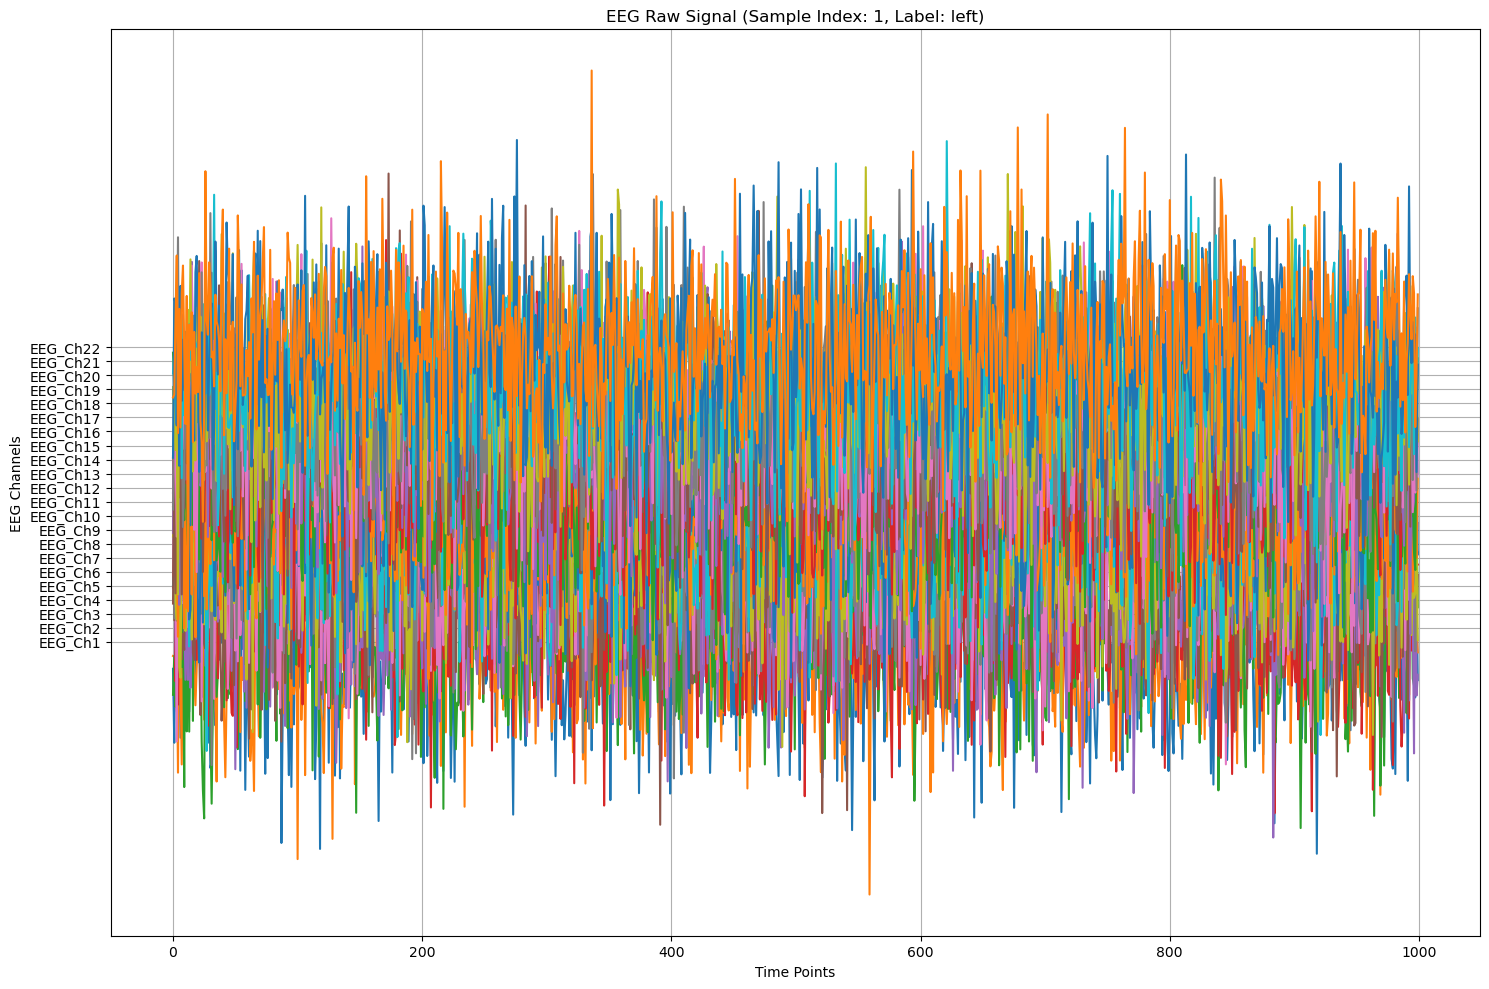


--- Raw vs. Normalized EEG Signal Comparison ---


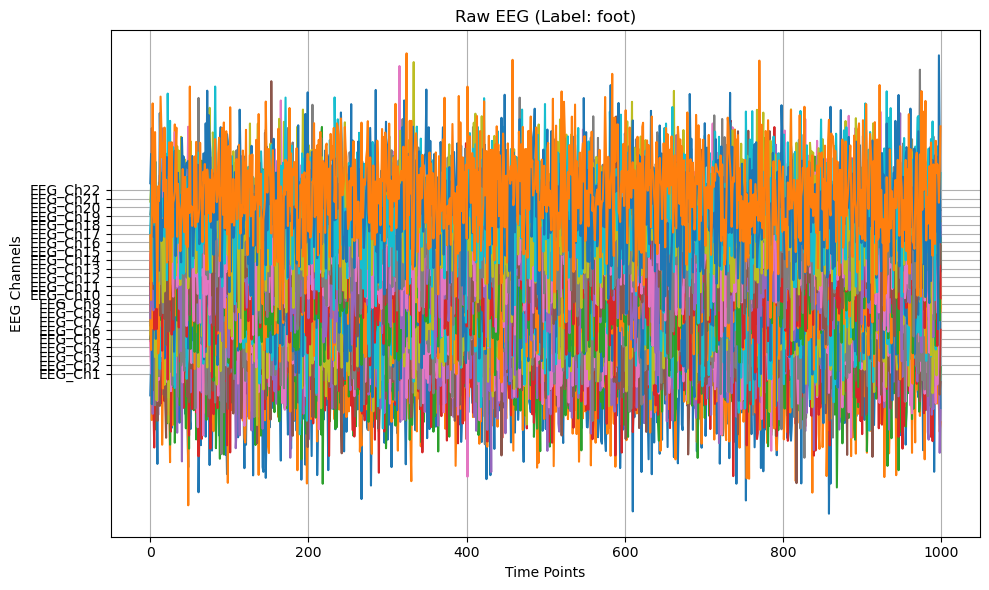

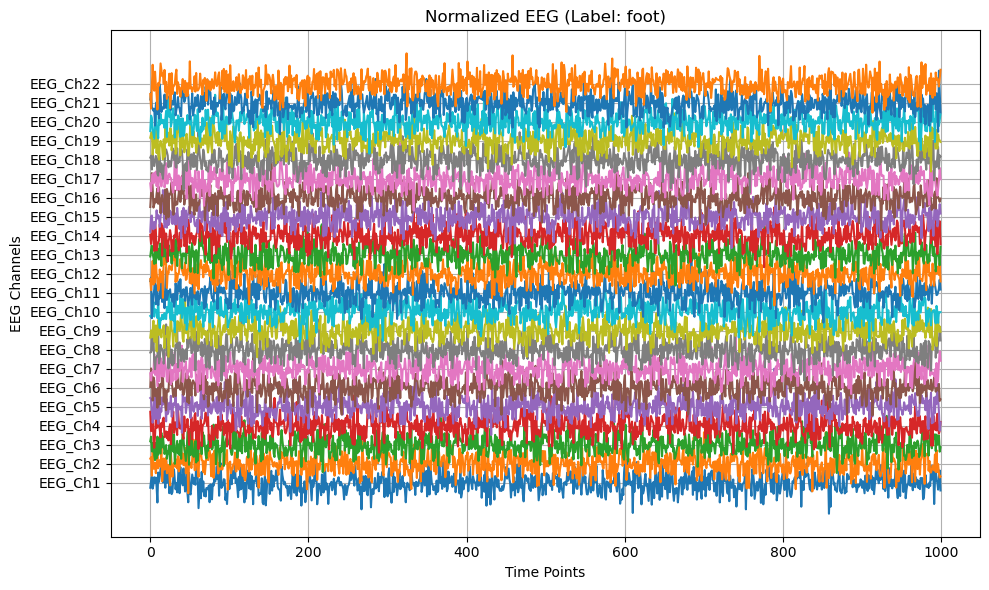


--- EEG Signal Frequency-Domain Visualization (FFT) ---


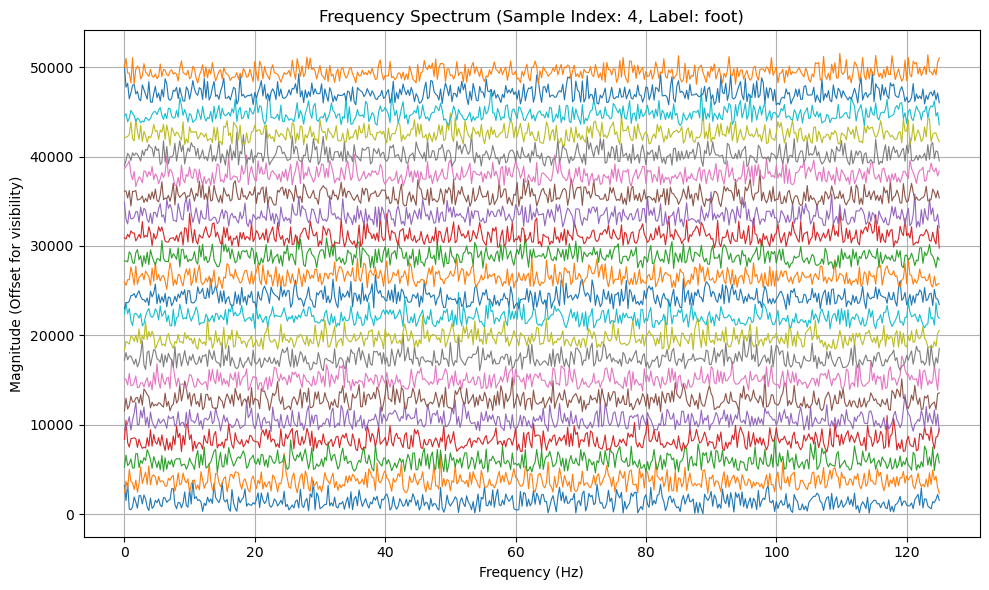


--- Spectrogram-like EEG Heatmap ---


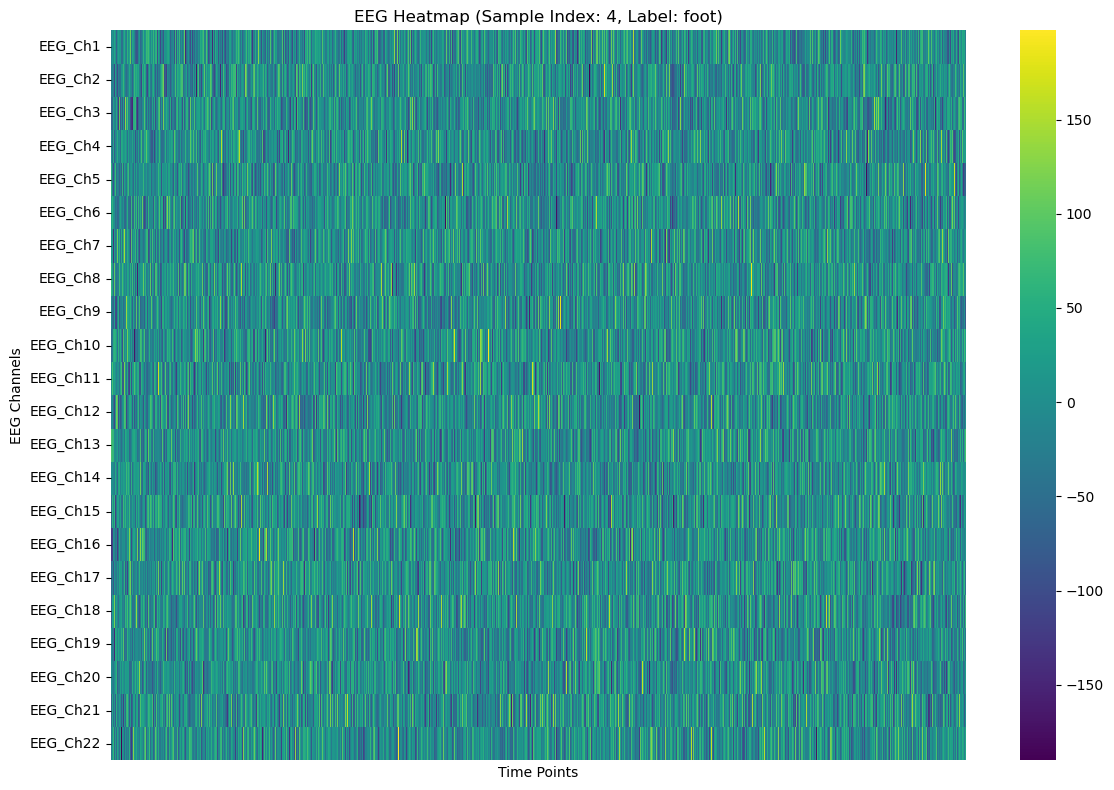


--- EEG Band Power Calculation ---


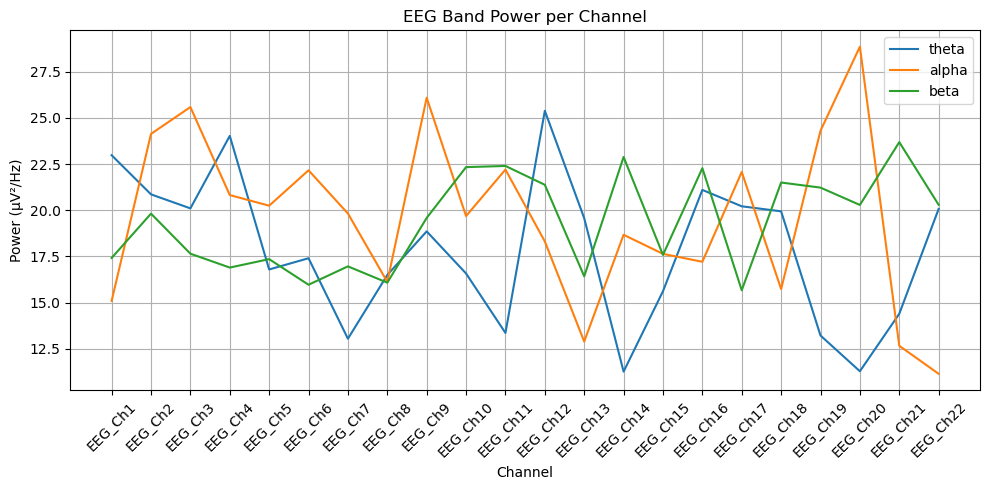


--- PCA and t-SNE Feature Visualization ---


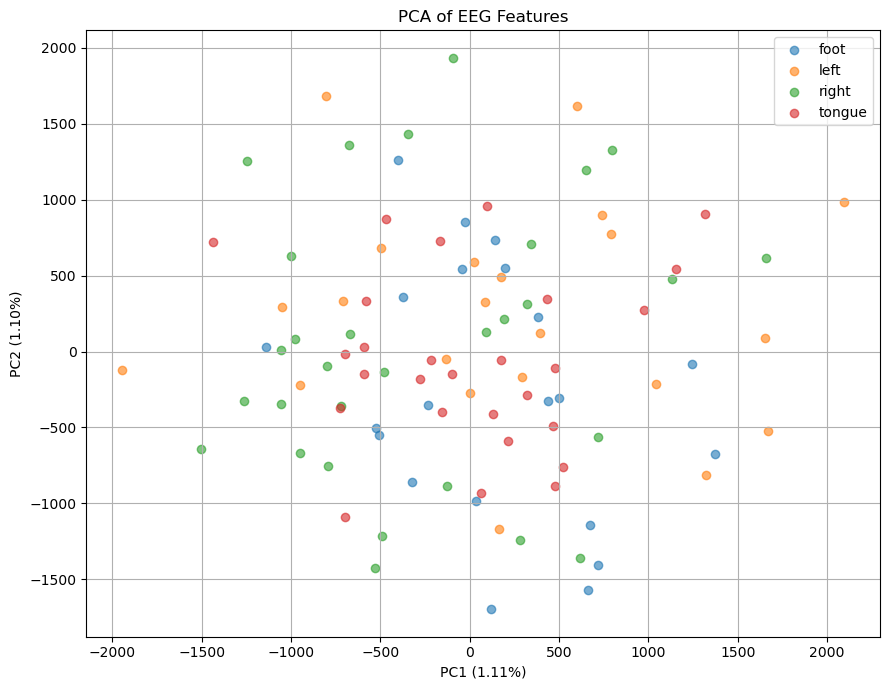

In [49]:
# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from scipy.fft import fft, rfftfreq
from scipy.signal import welch
import random

# --- Parameters for dummy data ---
n_samples = 100
n_channels = 22  # Standard for BCIC IV 2a
n_time_points = 1000  # Assuming 4 seconds at 250 Hz
sf = 250  # Sampling frequency

# Dummy raw EEG data (X)
X = np.random.randn(n_samples, n_channels, n_time_points) * 50

# Dummy labels (y)
labels = ['left', 'right', 'foot', 'tongue']
y = np.array(random.choices(labels, k=n_samples))

# EEG channel names
eeg_columns = [f'EEG_Ch{i+1}' for i in range(n_channels)]

# Normalize EEG data
scaler = StandardScaler()
X_reshaped = X.reshape(-1, n_time_points)
X_normalized_reshaped = scaler.fit_transform(X_reshaped)
X_normalized = X_normalized_reshaped.reshape(n_samples, n_channels, n_time_points)

# Frequency domain (FFT)
X_freq_real = np.abs(np.fft.rfft(X, axis=-1))

# Windowed features for PCA/t-SNE
X_windows = X  # Placeholder

# Label encoding
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_categorical = tf.keras.utils.to_categorical(y_encoded)

# --- Visualization: Raw EEG ---
print("--- Raw EEG Signal Visualization (Sample) ---")
left_indices = np.where(y == 'left')[0]
sample_idx = left_indices[0] if len(left_indices) > 0 else random.randint(0, n_samples - 1)
sample_data = X[sample_idx]

plt.figure(figsize=(15, 10))
for ch in range(sample_data.shape[0]):
    plt.plot(sample_data[ch] + ch * 10, label=f'Ch {eeg_columns[ch]}')
plt.yticks([ch * 10 for ch in range(sample_data.shape[0])], eeg_columns)
plt.title(f'EEG Raw Signal (Sample Index: {sample_idx}, Label: {y[sample_idx]})')
plt.xlabel("Time Points")
plt.ylabel("EEG Channels")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Comparison: Raw vs Normalized ---
print("\n--- Raw vs. Normalized EEG Signal Comparison ---")
target_class = 'foot'
class_indices = np.where(y == target_class)[0]
sample_idx = class_indices[0] if len(class_indices) > 0 else random.randint(0, n_samples - 1)
raw_sample = X[sample_idx]
norm_sample = X_normalized[sample_idx]
start_time, end_time = 0, raw_sample.shape[1]
raw_clip = raw_sample[:, start_time:end_time]
norm_clip = norm_sample[:, start_time:end_time]
time_points = np.arange(start_time, end_time)

# Raw EEG
plt.figure(figsize=(10, 6))
for ch in range(n_channels):
    plt.plot(time_points, raw_clip[ch] + ch * 10)
plt.yticks([ch * 10 for ch in range(n_channels)], eeg_columns)
plt.title(f'Raw EEG (Label: {target_class})')
plt.xlabel("Time Points")
plt.ylabel("EEG Channels")
plt.grid(True)
plt.tight_layout()
plt.show()

# Normalized EEG
plt.figure(figsize=(10, 6))
for ch in range(n_channels):
    plt.plot(time_points, norm_clip[ch] + ch * 2)
plt.yticks([ch * 2 for ch in range(n_channels)], eeg_columns)
plt.title(f'Normalized EEG (Label: {target_class})')
plt.xlabel("Time Points")
plt.ylabel("EEG Channels")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Frequency-Domain Visualization ---
print("\n--- EEG Signal Frequency-Domain Visualization (FFT) ---")
sample_freq = X_freq_real[sample_idx]
freqs = rfftfreq(n_time_points, d=1/sf)

plt.figure(figsize=(10, 6))
offset = np.max(sample_freq) * 0.5
for ch in range(n_channels):
    plt.plot(freqs, sample_freq[ch] + ch * offset, lw=0.8)
plt.title(f'Frequency Spectrum (Sample Index: {sample_idx}, Label: {y[sample_idx]})')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (Offset for visibility)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Heatmap ---
print("\n--- Spectrogram-like EEG Heatmap ---")
plt.figure(figsize=(12, 8))
sns.heatmap(sample_data, cmap='viridis', yticklabels=eeg_columns, xticklabels=False)
plt.title(f'EEG Heatmap (Sample Index: {sample_idx}, Label: {y[sample_idx]})')
plt.xlabel("Time Points")
plt.ylabel("EEG Channels")
plt.tight_layout()
plt.show()

# --- Band Power ---
print("\n--- EEG Band Power Calculation ---")
def bandpower(data, sf, band, window_sec=None):
    low, high = band
    nperseg = int(window_sec * sf) if window_sec else None
    freqs, psd = welch(data, sf, nperseg=nperseg)
    idx_band = np.logical_and(freqs >= low, freqs <= high)
    return np.mean(psd[idx_band]) if np.any(idx_band) else 0.0

bands = {'theta': (4, 7), 'alpha': (8, 13), 'beta': (14, 30)}
band_powers = {band: [] for band in bands}

for ch in range(n_channels):
    signal = sample_data[ch]
    for band, band_range in bands.items():
        band_powers[band].append(bandpower(signal, sf, band_range, window_sec=2))

plt.figure(figsize=(10, 5))
for band in bands:
    plt.plot(band_powers[band], label=band)
plt.xticks(np.arange(n_channels), eeg_columns, rotation=45)
plt.title("EEG Band Power per Channel")
plt.xlabel("Channel")
plt.ylabel("Power (μV²/Hz)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- PCA Visualization ---
print("\n--- PCA and t-SNE Feature Visualization ---")
X_flat = X_windows.reshape(n_samples, -1)
y_labels = np.argmax(y_categorical, axis=1)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_flat)

plt.figure(figsize=(9, 7))
for i in np.unique(y_labels):
    label = label_encoder.classes_[i] if i < len(label_encoder.classes_) else f'Class {i}'
    plt.scatter(X_pca[y_labels == i, 0], X_pca[y_labels == i, 1], label=label, alpha=0.6)
plt.title("PCA of EEG Features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# **Basic RNN Model Creation**

In [15]:
# Define input shape from X_train
channels = X.shape[1]
timesteps = X_train.shape[1]       # 50
features = X_train.shape[2]        # 22 * 2 = 44
num_classes = y_train.shape[1]     # 4

In [16]:
X.shape, y.shape

((100, 22, 1000), (100,))

# **CNN-LSTM**

In [73]:
def CNN_LSTM(input_shape, num_classes, dropoutRate=0.3, l2_reg = 0.002):
    input1 = Input(shape=input_shape)

    x = Conv1D(32, kernel_size=3, padding='same', activation='elu', kernel_regularizer=l2(l2_reg))(input1)
    x = BatchNormalization()(x)
    x = Dropout(dropoutRate)(x)

    x = Conv1D(64, kernel_size=3, padding='same', activation='elu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(dropoutRate)(x)

    x = LSTM(128, return_sequences=True, dropout=dropoutRate)(x)
    x = LSTM(64, dropout=dropoutRate)(x)

    x = Dense(64, activation='elu', kernel_regularizer=l2(l2_reg))(x)
    x = Dropout(dropoutRate)(x)
    x = Dense(num_classes, activation='softmax')(x)

    return Model(inputs=input1, outputs=x)

# **GRU Flatten Model**

In [74]:
def GRU_Flatten_Model(input_shape, num_classes):
    inputs = Input(shape=input_shape)
    gru_out = GRU(256, return_sequences=True)(inputs)
    flatten_out = Flatten()(gru_out)
    outputs = Dense(num_classes, activation='softmax')(flatten_out)
    return Model(inputs=inputs, outputs=outputs)

# **GRU Reqularized**

In [75]:
def GRU_Regularized_Model(input_shape, num_classes, dropout_rate=0.2, l2_reg=0.002):
    inputs = Input(shape=input_shape)
    
    # GRU layer with L2 regularization
    gru_out = GRU(256, return_sequences=True,
                  kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    
    # Dropout for regularization
    gru_out = Dropout(dropout_rate)(gru_out)
    
    # Flatten before dense layer
    flatten_out = Flatten()(gru_out)
    
    # Output layer
    outputs = Dense(num_classes, activation='softmax')(flatten_out)
    return Model(inputs=inputs, outputs=outputs)


# **Subject Invariant Training**

In [58]:
# === Choose your model ===
#model = CNN_LSTM(input_shape=(timesteps, features), num_classes=num_classes, dropoutRate=0.3, l2_reg = 0.002)

#model = GRU_Flatten_Model(input_shape=(timesteps, features), num_classes=num_classes)

model = GRU_Regularized_Model(input_shape=(timesteps, features),num_classes=num_classes,dropout_rate=0.2, l2_reg=0.002)



model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 50, 44)]          0         
                                                                 
 gru_3 (GRU)                 (None, 50, 256)           231936    
                                                                 
 dropout_7 (Dropout)         (None, 50, 256)           0         
                                                                 
 flatten_3 (Flatten)         (None, 12800)             0         
                                                                 
 dense_7 (Dense)             (None, 4)                 51204     
                                                                 
Total params: 283,140
Trainable params: 283,140
Non-trainable params: 0
_________________________________________________________________


In [59]:
early_stopping = EarlyStopping(monitor='val_accuracy', 
                               patience=6, 
                               restore_best_weights=True, 
                               mode='max')
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', 
                                 factor=0.5, 
                                 patience=5, 
                                 min_lr=1e-6)

history = model.fit(X_train, y_train,
                    batch_size=32,
                    epochs=100,
                    validation_data=(X_test, y_test),
                    callbacks=[early_stopping, lr_scheduler],
                    verbose=1)

test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")

Epoch 1/100
116/116 [==============================] - 7s 50ms/step - loss: 1.6913 - accuracy: 0.2827 - val_loss: 1.5547 - val_accuracy: 0.3265 - lr: 5.0000e-04
Epoch 2/100
116/116 [==============================] - 4s 34ms/step - loss: 1.4477 - accuracy: 0.3798 - val_loss: 1.4966 - val_accuracy: 0.3373 - lr: 5.0000e-04
Epoch 3/100
116/116 [==============================] - 5s 40ms/step - loss: 1.3244 - accuracy: 0.4569 - val_loss: 1.4840 - val_accuracy: 0.3514 - lr: 5.0000e-04
Epoch 4/100
116/116 [==============================] - 5s 42ms/step - loss: 1.2170 - accuracy: 0.5052 - val_loss: 1.4471 - val_accuracy: 0.3970 - lr: 5.0000e-04
Epoch 5/100
116/116 [==============================] - 4s 33ms/step - loss: 1.1108 - accuracy: 0.5705 - val_loss: 1.4214 - val_accuracy: 0.4078 - lr: 5.0000e-04
Epoch 6/100
116/116 [==============================] - 4s 34ms/step - loss: 1.0095 - accuracy: 0.6177 - val_loss: 1.3866 - val_accuracy: 0.4338 - lr: 5.0000e-04
Epoch 7/100
116/116 [=============

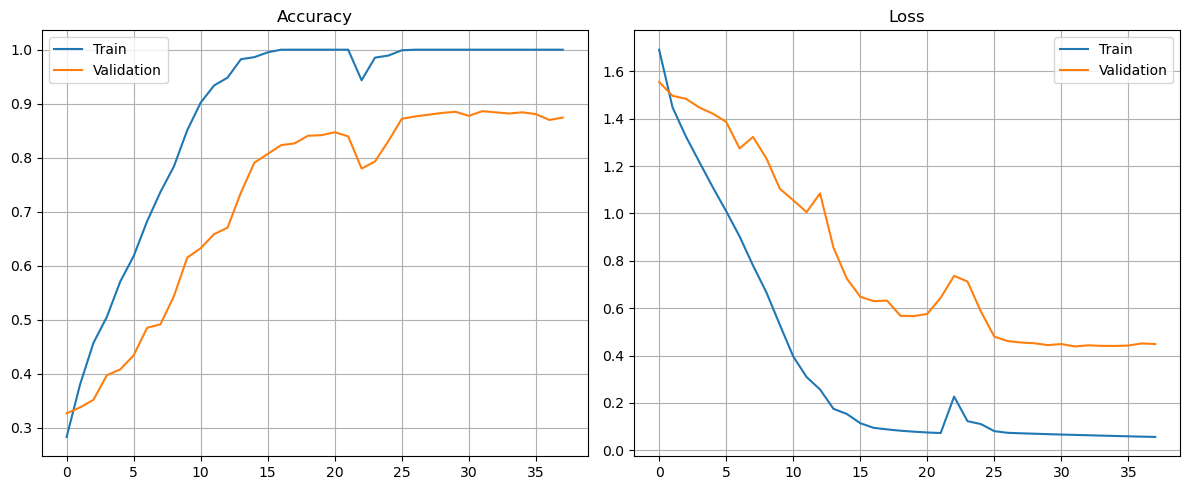

In [60]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("GRU Regularized Model.png")
plt.show()

29/29 [==============================] - 0s 15ms/step


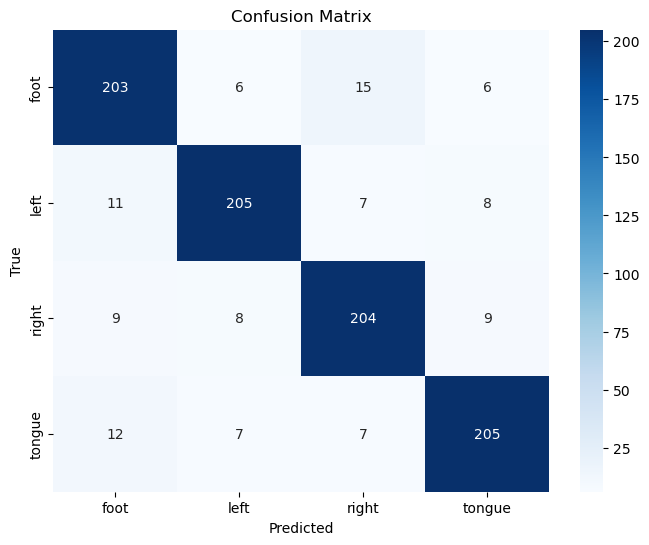

GRU Regularized Classification Report:
              precision    recall  f1-score   support

        foot       0.86      0.88      0.87       230
        left       0.91      0.89      0.90       231
       right       0.88      0.89      0.88       230
      tongue       0.90      0.89      0.89       231

    accuracy                           0.89       922
   macro avg       0.89      0.89      0.89       922
weighted avg       0.89      0.89      0.89       922

Accuracy: 0.8861


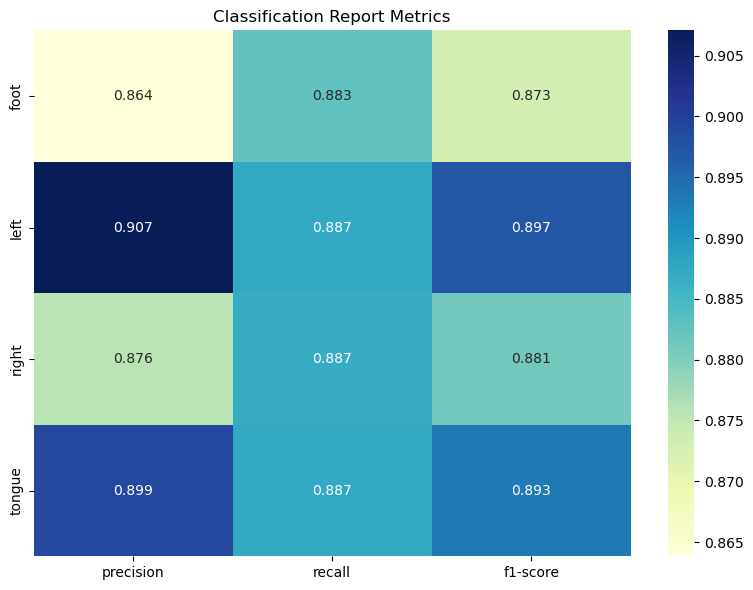

In [96]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred)
labels = label_encoder.classes_

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.savefig("GRUFlatten model confusion_matrix.png")
plt.show()

print("GRU Regularized Classification Report:")
print(classification_report(y_true, y_pred, target_names=labels))


report = classification_report(y_true, y_pred, target_names=labels,output_dict=True)
report_df = pd.DataFrame(report).transpose()

plt.figure(figsize=(8, 6))
sns.heatmap(report_df.iloc[:-3, :-1].astype(float), 
            annot=True, cmap='YlGnBu', fmt='.3f')
plt.title('Classification Report Metrics')
plt.tight_layout()
plt.savefig('GRU Regularized classification_report_heatmap.png', dpi=300)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f}")


# **Subjectwise Training**

In [104]:
results_log = {"Subject":[],"Model_name":[],"Accuracy":[],"Precision":[],"Recall":[],"F1_Score":[], "Kappa":[]}

In [119]:
for sub_num in range(1,10):
    sub_df = df[df["patient"]==sub_num]
    sub_df.reset_index(drop=True)
    sub_df[eeg_columns] = sub_df[eeg_columns].apply(pd.to_numeric, errors='coerce')
    sub_df = sub_df.dropna()

    # Group by epochs
    grouped = df.groupby('epoch')
    X, y = [], []
    target_length = 201

    for epoch, group in grouped:
        data = group[eeg_columns].values.T
        if data.shape[1] > target_length:
            data = data[:, :target_length]
        elif data.shape[1] < target_length:
            pad_width = target_length - data.shape[1]
            data = np.pad(data, ((0, 0), (0, pad_width)), mode='constant')
        X.append(data)
        y.append(group['label'].iloc[0])

    X = np.array(X)
    y = np.array(y)

    window_size = 50
    stride = 10
    X_windows, y_windows = [], []

    for i in range(n_samples):
        data = X_normalized[i]
        freq_data = X_freq[i]
        num_windows = (n_time_points - window_size) // stride + 1

        for w in range(num_windows):
            start = w * stride
            end = start + window_size
            window = data[:, start:end]

            freq_start = (start * (n_time_points // 2 + 1)) // n_time_points
            freq_end = (end * (n_time_points // 2 + 1)) // n_time_points
            freq_window = freq_data[:, freq_start:freq_end]

            if freq_window.shape[1] < window_size:
                freq_window = np.pad(freq_window, ((0, 0), (0, window_size - freq_window.shape[1])), mode='constant')
            elif freq_window.shape[1] > window_size:
                freq_window = freq_window[:, :window_size]

            combined = np.stack([window, freq_window], axis=-1)
            X_windows.append(combined)
            y_windows.append(y[i])

    X_windows = np.array(X_windows)
    y_windows = np.array(y_windows)

    # Encode labels
    label_encoder = LabelEncoder()
    y_encoded = label_encoder.fit_transform(y_windows)
    y_categorical = tf.keras.utils.to_categorical(y_encoded)
    # Reshape: (samples, time_steps, channels, features) -> (samples, time_steps, channels * features)
    X_windows = X_windows.transpose(0, 2, 1, 3)
    X_windows = X_windows.reshape(X_windows.shape[0], X_windows.shape[1], X_windows.shape[2] * X_windows.shape[3])
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X_windows, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical)
    for model_name in ["CNN_LSTM", "GRU_Regularized", "GRU_flatten"]:
        if model_name == "CNN_LSTM":
            model = CNN_LSTM(input_shape=(timesteps, features), num_classes=num_classes, dropoutRate=0.3, l2_reg = 0.002)

        if model_name == "GRU_Regularized":
            model = GRU_Regularized_Model(input_shape=(timesteps, features),num_classes=num_classes,dropout_rate=0.2, l2_reg=0.002)

        if model_name == "GRU_flatten":
            model = GRU_Flatten_Model(input_shape=(timesteps, features), num_classes=num_classes)

        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

        early_stopping = EarlyStopping(monitor='val_accuracy', 
                            patience=6, 
                            restore_best_weights=True, 
                                mode='max')
        lr_scheduler = ReduceLROnPlateau(monitor='val_loss', 
                                        factor=0.5, 
                                        patience=5, 
                                        min_lr=1e-6)
        
        print(f"Starting training of Subject number : {sub_num} on the {model_name} model...")
        history = model.fit(X_train, y_train,
                            batch_size=32,
                            epochs=100,
                            validation_data=(X_test, y_test),
                            callbacks=[early_stopping, lr_scheduler],
                            verbose=1)

        test_loss, test_accuracy = model.evaluate(X_test, y_test)
        
        y_pred_probs = model.predict(X_test)

        y_pred = np.argmax(y_pred_probs, axis=1)
        y_true = np.argmax(y_test, axis=1)

        report = classification_report(y_true, y_pred, target_names=labels,output_dict=True)
        report_df = pd.DataFrame(report).transpose()

        cohen_kappa_score(y_pred, y_true)
        accuracy = accuracy_score(y_true, y_pred)
        precision = round(report_df["precision"]["weighted avg"], 4)
        recall = round(report_df["recall"]["weighted avg"], 4)
        f1_score = round(report_df["f1-score"]["weighted avg"], 4)

        results_log["Subject"].append(sub_num)
        results_log["Model_name"].append(model_name)
        results_log["Accuracy"].append(accuracy)
        results_log["Precision"].append(precision)
        results_log["Recall"].append(recall)
        results_log["F1_Score"].append(f1_score)
        results_log["Kappa"].append(cohen_kappa_score)

C:\Users\Md Nazmus Saquib\AppData\Local\Temp\ipykernel_24708\2812993512.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_df[eeg_columns] = sub_df[eeg_columns].apply(pd.to_numeric, errors='coerce')


Starting training of Subject number : 1 on the CNN_LSTM model...
Epoch 1/100
253/253 [==============================] - 33s 113ms/step - loss: 1.6428 - accuracy: 0.2516 - val_loss: 1.5938 - val_accuracy: 0.2511 - lr: 5.0000e-04
Epoch 2/100
253/253 [==============================] - 30s 117ms/step - loss: 1.5634 - accuracy: 0.2570 - val_loss: 1.5255 - val_accuracy: 0.2862 - lr: 5.0000e-04
Epoch 3/100
253/253 [==============================] - 28s 112ms/step - loss: 1.5085 - accuracy: 0.2846 - val_loss: 1.4857 - val_accuracy: 0.2916 - lr: 5.0000e-04
Epoch 4/100
253/253 [==============================] - 29s 113ms/step - loss: 1.4682 - accuracy: 0.3077 - val_loss: 1.4576 - val_accuracy: 0.3020 - lr: 5.0000e-04
Epoch 5/100
253/253 [==============================] - 29s 113ms/step - loss: 1.4370 - accuracy: 0.3169 - val_loss: 1.4254 - val_accuracy: 0.3159 - lr: 5.0000e-04
Epoch 6/100
253/253 [==============================] - 29s 113ms/step - loss: 1.4071 - accuracy: 0.3445 - val_loss: 1.44

C:\Users\Md Nazmus Saquib\AppData\Local\Temp\ipykernel_24708\2812993512.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_df[eeg_columns] = sub_df[eeg_columns].apply(pd.to_numeric, errors='coerce')


Starting training of Subject number : 2 on the CNN_LSTM model...
Epoch 1/100
253/253 [==============================] - 33s 116ms/step - loss: 1.6411 - accuracy: 0.2617 - val_loss: 1.5912 - val_accuracy: 0.2704 - lr: 5.0000e-04
Epoch 2/100
253/253 [==============================] - 28s 111ms/step - loss: 1.5603 - accuracy: 0.2873 - val_loss: 1.5304 - val_accuracy: 0.2986 - lr: 5.0000e-04
Epoch 3/100
253/253 [==============================] - 30s 117ms/step - loss: 1.5051 - accuracy: 0.3119 - val_loss: 1.5046 - val_accuracy: 0.2842 - lr: 5.0000e-04
Epoch 4/100
253/253 [==============================] - 29s 114ms/step - loss: 1.4663 - accuracy: 0.3291 - val_loss: 1.4574 - val_accuracy: 0.3178 - lr: 5.0000e-04
Epoch 5/100
253/253 [==============================] - 30s 119ms/step - loss: 1.4341 - accuracy: 0.3454 - val_loss: 1.5190 - val_accuracy: 0.3159 - lr: 5.0000e-04
Epoch 6/100
253/253 [==============================] - 37s 146ms/step - loss: 1.4044 - accuracy: 0.3452 - val_loss: 1.41

KeyboardInterrupt: 